 # Лабораторная работа 3. Разведочный анализ данных (EDA) - фонемы



 запускать из `labs/lab3_g2p/` после `prepare_lexicon.py`.



 анализ ведётся на `train`-части

In [11]:
%load_ext autoreload
%autoreload 2

import csv
import os
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import tqdm
from praatio import textgrid

import g2p
from g2p import *
import prepare_metadata

ALIGN_DIR = '../../data/RUSLAN_align/v2/'
MFA_DICT = g2p.MFA_DICT_PATH


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
DATA = g2p.BASE / 'data'
raw = load_tokens(DATA / 'alignment_raw.csv')
raw = raw[raw.token != SIL].copy()
raw['spn'] = raw.phones.str.split().map(lambda p: 'spn' in p)
raw['unpronounced'] = raw.phones == ''

# токены с эталоном: инвентарь, длительности, EDA фонем
tokens = raw[~raw.spn & ~raw.unpronounced].copy()
tokens['phone_list'] = tokens.phones.str.split()
train, test = tokens[tokens.set == 'train'], tokens[tokens.set == 'test']

# итоговые данные работы: после удаления предложений со spn
clean = load_tokens(DATA / 'tokens_phones.csv')
clean_train, clean_test = clean[clean.set == 'train'], clean[clean.set == 'test']
sil = load_tokens()   # с паузами, нужен для evaluate
sil_train, sil_test = sil[sil.set == 'train'], sil[sil.set == 'test']

lex_df = pd.read_csv(g2p.LEXICON_PATH, sep='|', quoting=csv.QUOTE_NONE, keep_default_na=False)
lexicon = {w: Counter(dict(zip(g.phones, g.frequency))) for w, g in lex_df.groupby('token')}
mfa = load_mfa_dict()


def per_of(df, pron_of):
    """PER по словам: pron_of(token) возвращает список фонем."""
    ref = [p.split() for p in df.phones]
    hyp = [pron_of(t) for t in df.token]
    return sum(map(edit_distance, ref, hyp)) / sum(map(len, ref))


print(f'токенов: {len(tokens)} (выброшено без транскрипции: {raw.unpronounced.sum()}, из них со spn: {raw.spn.sum()}), '
      f'\nпредложений: {tokens.id.nunique()}, \nтипов в лексиконе (train): {len(lexicon)}, '
      f'\nслов в словаре mfa: {len(mfa)}')

токенов: 244924 (выброшено без транскрипции: 0, из них со spn: 708), 
предложений: 21255, 
типов в лексиконе (train): 39621, 
слов в словаре mfa: 452273


 ## 1. какие фонемы есть в корпусе, как они соотносятся с IPA, какие у них длительности

In [13]:
phone_counts = Counter(p for ph in train.phone_list for p in ph)       # частоты по train
all_counts = Counter(p for ph in tokens.phone_list for p in ph)        # по всему корпусу
inventory = (pd.DataFrame(phone_counts.items(), columns=['phone', 'count'])
             .sort_values('count', ascending=False).reset_index(drop=True))
inventory['share'] = inventory['count'] / inventory['count'].sum()
# кодпоинты нужны, чтобы заметить визуально одинаковые, но разные символы (g и ɡ)
inventory['codepoints'] = inventory.phone.map(lambda p: ' '.join(f'{ord(c):04x}' for c in p))

VOWELS = set('a æ e ɛ i o ɵ u ʉ ɐ ə ɪ ʊ ɨ'.split())
PAL, DENTAL = '\u02b2', '\u032a'
SOFT_OTHER = set('ʎ ɲ c ɟ ç ɕ tɕ'.split())   # мягкие согласные, записанные без ʲ

def phone_class(p):
    if p in VOWELS:
        return 'гласная'
    if PAL in p or p in SOFT_OTHER:
        return 'мягкая согласная'
    if DENTAL in p:
        return 'зубная согласная'
    return 'прочая согласная'

inventory['class'] = inventory.phone.map(phone_class)
print(f'фонем в корпусе: {len(inventory)}')
display(inventory.groupby('class')['count'].agg(['size', 'sum']))
display(inventory)


фонем в корпусе: 55


,size,sum
class,,
гласная,14,465894
зубная согласная,7,166823
мягкая согласная,17,178588
прочая согласная,17,285951


,phone,count,share,codepoints,class
0,ɪ,87209,7.947917e-02,026a,гласная
1,ə,83770,7.634499e-02,0259,гласная
2,ɐ,58323,5.315350e-02,0250,гласная
3,t̪,48892,4.455843e-02,0074 032a,зубная согласная
4,a,48689,4.437342e-02,0061,гласная
5,j,42966,3.915768e-02,006a,прочая согласная
6,n̪,42166,3.842859e-02,006e 032a,зубная согласная
7,s̪,36413,3.318551e-02,0073 032a,зубная согласная
8,e,36099,3.289934e-02,0065,гласная
9,r,35292,3.216387e-02,0072,прочая согласная


In [14]:
DUR_CACHE = 'data/phone_durations.csv'

def read_durations(ids):
    rows = []
    for utt in tqdm.tqdm(ids):
        _, phone_tier = textgrid.openTextgrid(f'{ALIGN_DIR}{utt}.TextGrid', True).tiers
        rows += [(utt, unicodedata.normalize('NFC', e.label).replace('ː', ''), e.end - e.start)
                for e in phone_tier.entries if e.label]
    return pd.DataFrame(rows, columns=['id', 'phone', 'dur'])

if os.path.isfile(DUR_CACHE):
    durations = pd.read_csv(DUR_CACHE, keep_default_na=False)
else:
    durations = read_durations(sorted(tokens.id.unique()))
    durations.to_csv(DUR_CACHE, index=False)
durations = durations[durations.phone != 'spn']


,count,mean,median,std,cv
phone,,,,,
ɪ,87209,17.483,10.000,29.637,1.695
ə,83770,39.705,30.000,34.161,0.860
ɐ,58323,63.917,60.000,20.773,0.325
t̪,48892,78.824,70.000,32.023,0.406
a,48689,88.820,90.000,35.477,0.399
j,42966,65.244,50.000,39.203,0.601
n̪,42166,67.837,60.000,30.728,0.453
s̪,36413,101.683,100.000,33.339,0.328
e,36099,73.548,70.000,34.763,0.473


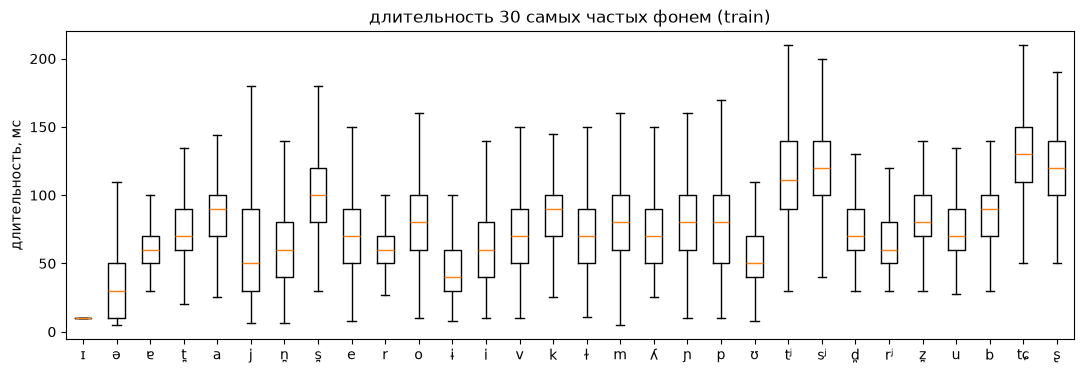

In [15]:
train_ids = set(train.id)
dur_tr = durations[durations.id.isin(train_ids)]

dur_stats = (dur_tr.groupby('phone').dur.agg(['count', 'mean', 'median', 'std'])
             .assign(cv=lambda d: d['std'] / d['mean']))
dur_stats[['mean', 'median', 'std']] *= 1000  # в мс
display(dur_stats.sort_values('count', ascending=False).round(3))

top = list(inventory.phone.head(30))
by_phone = dur_tr.groupby('phone').dur
fig, ax = plt.subplots(figsize=(13, 4))
ax.boxplot([by_phone.get_group(p) * 1000 for p in top], showfliers=False)
ax.set_xticklabels(top)
ax.set_ylabel('длительность, мс')
ax.set_title('длительность 30 самых частых фонем (train)')
plt.savefig('img/phone_durations.png', dpi=150, bbox_inches='tight')
plt.show()


In [16]:
# базовые фонемы русского по таблице из википедии
IPA_BASE = set('p b t d k \u0261 f v s z ʂ ʐ ɕ x ts tɕ m n l ɫ r j'.split())

def base(p):
    return p.replace(PAL, '').replace(DENTAL, '')

# фонемы корпуса, которые не объясняются таблицей ipa
display(inventory[~inventory.phone.map(base).isin(IPA_BASE | VOWELS)])


,phone,count,share,codepoints,class
17,ʎ,25509,2.324799e-02,028e,мягкая согласная
18,ɲ,23708,2.160663e-02,0272,мягкая согласная
37,c,7954,7.248992e-03,0063,мягкая согласная
45,ɟ,3189,2.906341e-03,025f,мягкая согласная
49,ç,460,4.192276e-04,00e7,мягкая согласная
50,tʂ,257,2.342206e-04,0074 0282,прочая согласная
51,dʐ,205,1.868297e-04,0064 0290,прочая согласная
52,ɣ,24,2.187274e-05,0263,прочая согласная
53,ʑ,10,9.113643e-06,0291,прочая согласная
54,d̪z̪,1,9.113643e-07,0064 032a 007a 032a,зубная согласная


 **выводы по п. 1:**



 - почти все фонемы корпуса объясняются таблицей ipa. не объясняются только мягкие ʎ, ɲ, c, ɟ, ç, аффрикаты tʂ, dʐ и редкие ɣ, ʑ, d̪z̪.

 - запись непоследовательна: мягкие л и н записаны как ʎ и ɲ, а палатальные c, ɟ, ç (к, г, х перед мягким) без ʲ. это особенность записи, а не ошибка разметки; в классификации они учтены как мягкие.

 - часть фонем состоит из нескольких символов (зубность, мягкость, аффрикаты), поэтому фонема в коде это строка, а не символ.

 - самые долгие фонемы: ɕ, tʂ, dʐ, ç (у ʑ данных слишком мало, чтобы судить). они же самые стабильные по длительности.

 - самые изменчивые по длительности: редуцированные гласные ɪ, ə, ʉ, ɨ. ɪ часто почти исчезает: типичная длительность один-два кадра выравнивания.

 - для g2p: инвентарь оставляем как в корпусе, фонемы не переименовываем.

 ## 2. самые редкие фонемы

,phone,count,share,codepoints,class,examples
40,t̪s̪,4964,4.524013e-03,0074 032a 0073 032a,зубная согласная,"[наконец, отец, двадцать, лицо, тридцать]"
41,ɵ,4630,4.219617e-03,0275,гласная,"[все, её, ещё, произнёс, причём]"
42,bʲ,4186,3.814971e-03,0062 02b2,мягкая согласная,"[без, тебя, тебе, себя, себе]"
43,ɕ,4114,3.749353e-03,0255,мягкая согласная,"[ещё, вообще, общем, женщина, ощущение]"
44,zʲ,3455,3.148764e-03,007a 02b2,мягкая согласная,"[здесь, жизни, жизнь, произнёс, друзья]"
45,ɟ,3189,2.906341e-03,025f,мягкая согласная,"[где, деньги, книги, бумаги, многие]"
46,æ,3023,2.755054e-03,00e6,гласная,"[дядя, пять, опять, чаще, отвечает]"
47,ʉ,2125,1.936649e-03,0289,гласная,"[люди, чуть, людей, союзе, ощущение]"
48,fʲ,1627,1.482790e-03,0066 02b2,мягкая согласная,"[кофе, любовь, фима, шофёр, впервые]"
49,ç,460,4.192276e-04,00e7,мягкая согласная,"[стихи, хиггинс, эпохи, духе, слухи]"


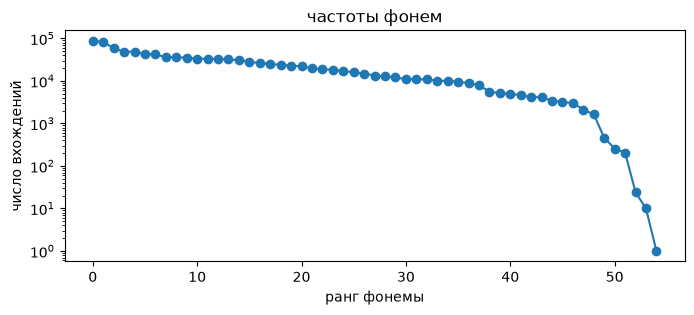

In [17]:
exploded = train[['token', 'phone_list']].explode('phone_list')
rare = inventory.tail(15).copy()
rare['examples'] = rare.phone.map(
    lambda p: exploded[exploded.phone_list == p].token.value_counts().head(5).index.tolist())
display(rare)

plt.figure(figsize=(8, 3))
plt.semilogy(inventory['count'].values, 'o-')
plt.xlabel('ранг фонемы')
plt.ylabel('число вхождений')
plt.title('частоты фонем')
plt.savefig('img/phone_freq.png', dpi=150, bbox_inches='tight')
plt.show()


 **выводы по п. 2:**



 - самые редкие фонемы: d̪z̪ (единичный случай, имя «зальцбург»), ʑ и ɣ (единицы и десятки примеров), затем dʐ, tʂ, ç (сотни).

 - слова настоящие:

   - ɣ: «ого», «бухгалтер», «сверхсрочников».

   - ʑ: «уезжал», «заезженную».

   - dʐ: «пиджак», «джинсы», «джон».

   - tʂ: «лучше», «лучший».

   - ç: «стихи», «эпохи», «слухи».

 - это аллофоны и результат акустического выбора MFA, ошибок разметки нет.

 - решение:

   - все эти фонемы уже есть в целевом списке, приводить к нему нечего.

   - ɣ и ʑ слить с ближайшими (ɣ→ɡ, ʑ→ʐ): примеров слишком мало, чтобы выучить эмбеддинг. это делается при сборке метаданных для следующей работы (`prepare_metadata.MERGE_RARE`), а не в g2p.

   - d̪z̪ оставить в инвентаре без примеров.

   - dʐ, tʂ, ç оставить: примеров достаточно, слова разные.

   - предложения выбрасывать из-за редких фонем не нужно.

 ## 3. oov-слова относительно `russian_mfa.dict` и `lexicon.csv`



 остаток: слова, которых нет ни в лексиконе train, ни в словаре mfa. по ним считается порог 0.20.

In [18]:
lex_words, mfa_words = set(lexicon), set(mfa)

def coverage(df):
    out = {}
    for level, d in [('tokens', df), ('types', df.drop_duplicates('token'))]:
        in_lex, in_mfa = d.token.isin(lex_words), d.token.isin(mfa_words)
        out[level] = {'нет в лексиконе': (~in_lex).mean(),
                      'нет в словаре mfa': (~in_mfa).mean(),
                      'нет нигде': (~in_lex & ~in_mfa).mean()}
    return pd.DataFrame(out)

raw_train, raw_test = raw[raw.set == 'train'], raw[raw.set == 'test']
display(pd.concat({'train': coverage(raw_train), 'test': coverage(raw_test),
                   'all': coverage(raw)}, axis=1))

residual = raw_test[~raw_test.token.isin(lex_words | mfa_words)]
print(f'остаток в test: {len(residual)} токенов ({len(residual) / len(raw_test):.2%}), '
      f'{residual.token.nunique()} типов, из них со spn: {residual.spn.mean():.1%}')
display(residual.groupby('token').agg(count=('token', 'size'), phones=('phones', 'first'))
        .sort_values('count', ascending=False).head(30))


train                test                 all          
                     tokens     types    tokens     types    tokens     types
нет в лексиконе    0.008743  0.037367  0.125123  0.336558  0.031914  0.151276
нет в словаре mfa  0.059310  0.166938  0.061549  0.130553  0.059756  0.174389
нет нигде          0.004128  0.016448  0.028709  0.079405  0.009022  0.041707

остаток в test: 1404 токенов (2.87%), 1346 типов, из них со spn: 10.3%


,count,phones
token,,
лёву,3,spn
лёгкую,3,spn
лиля,3,ʎ i ʎ ə
хрущёвской,3,spn
циничного,3,t̪s̪ ɨ ɲ i tɕ n̪ ə v ə
эпштейна,2,ɪ p ʂ t̪ ɛ j n̪ ə
зависимой,2,z̪ ɐ vʲ i sʲ ɪ m ə j
крейцерова,2,c rʲ e j t̪s̪ ɨ r o v ə
издательские,2,ɪ z̪ d̪ a tʲ ɪ ʎ s̪ c ɪ j e


 **выводы по п. 3:**



 - считалось по сырой таблице `raw`, в которой токены со spn остаются.

 - на train лексикон покрывает почти всё, на test заметная часть слов в нём отсутствует, особенно если считать по типам: в тесте много редких словоформ.

 - словарь mfa покрывает test заметно лучше лексикона, по типам разница ещё сильнее. он нужен как запасной источник.

 - после обоих словарей остаётся небольшой остаток по токенам, но по типам он ощутимее: это редкие формы и имена.

 - в остатке слова со spn составляют лишь малую часть. у большинства остальных эталонные фонемы есть, но ни лексикон, ни словарь их не знают: для них нужны правила.

 ## 4. разметка на примерах со spn

In [19]:
sp = raw[raw.spn]
print(f'токенов со spn: {len(sp)} ({raw.spn.mean():.2%}), '
      f'предложений: {sp.id.nunique()} из {raw.id.nunique()}, типов слов: {sp.token.nunique()}')
print('по выборкам:', sp.groupby('set').size().to_dict())
print('доля этих слов, которые есть в словаре MFA:',
      sp.drop_duplicates('token').token.isin(mfa_words).mean())
print('предложений с unpronounced-токеном (их выбросит prepare_lexicon):',
      raw.groupby('id').unpronounced.any().sum())
print('осталось бы предложений, если выбросить все со spn:',
      raw[~raw.groupby('id').spn.transform('any')].id.nunique())
display(sp.token.value_counts().head(40))


токенов со spn: 708 (0.29%), предложений: 677 из 21255, типов слов: 526
по выборкам: {'test': 146, 'train': 562}
доля этих слов, которые есть в словаре MFA: 0.005703422053231939
предложений с unpronounced-токеном (их выбросит prepare_lexicon): 0
осталось бы предложений, если выбросить все со spn: 20578


token
лёву               7
пино-гри           6
лёве               5
казённой           5
лёгкую             5
лёвы               5
тёмных             5
наделён            5
кремлёвские        5
лёлик              5
безнадёжной        4
стеснённых         4
о'кей              4
электромонтёр      4
серёжу             4
марксистско        4
хрущёвской         4
фёдорович          4
захламлённый       3
далёкое            3
хиллс              3
чёрствые           3
серёга             3
напряжённой        3
напряжённая        3
отчётливыми        3
чёртовой           3
электромонтёром    3
отведённой         3
лёвка              3
хиллсе             3
йоркским           3
пятёрочку          3
дановер            3
анджелеса          3
беверли-хиллс      3
подёнщина          3
хрущёвская         3
мидл               3
стаф               3
Name: count, dtype: int64

 **выводы по п. 4:**



 - в выравнивании только предложения, прошедшие фильтр первой работы, поэтому цифр, латиницы и аббревиатур в нём нет и проверить на них MFA нельзя.

 - spn стоит у малой доли токенов и затрагивает малую долю предложений.

 - почти всех этих слов нет в словаре MFA, поэтому для них нет эталонных фонем.

 - по списку частых видно две группы: слова с «ё» (лёву, казённой, тёмных, хрущёвской) и иностранные имена и названия (хиллс, анджелеса, о'кей, пино-гри).

 - решение: токены со spn не берём в лексикон и в оценку (`prepare_lexicon.py` их пропускает, `evaluate` отбирает по флагу `unpronounced`). предложения со spn при сборке данных для следующей работы выбрасываются целиком (`prepare_metadata.py`), как требует задание: потеря небольшая, перевыравнивание не стоит затрат.

 ## 5. омографы, `все` / `всё`, что говорит словарь

In [20]:
# 1) слова clean_test, которые есть в лексиконе: чистый «самый частый вариант»
t_in = clean_test[clean_test.token.isin(lex_words)]
print('clean_test, в лексиконе:', per_of(t_in, lambda t: lexicon[t].most_common(1)[0][0].split()))

# 2) слова clean_test, которых нет в лексиконе: берём словарь MFA
t_oov = clean_test[~clean_test.token.isin(lex_words) & clean_test.token.isin(mfa_words)]
print('clean_test, не в лексиконе, словарь MFA:', per_of(t_oov, lambda t: mfa[t]))
print('доля таких слов в test:', len(t_oov) / len(clean_test))


clean_test, в лексиконе: 0.010324291021787427
clean_test, не в лексиконе, словарь MFA: 0.0063979358100102685
доля таких слов в test: 0.0952461980219079


In [21]:
multi = {w: c for w, c in lexicon.items() if len(c) > 1}
total = sum(sum(c.values()) for c in lexicon.values())
in_multi = sum(sum(c.values()) for c in multi.values())
minority = {w: sum(c.values()) - c.most_common(1)[0][1] for w, c in multi.items()}
print(f'типов с несколькими произношениями: {len(multi)} из {len(lexicon)}')
print(f'токенов clean_train в таких типах: {in_multi / total:.2%}, '
      f'не покрыто самым частым вариантом: {sum(minority.values()) / total:.2%}')
print(f'PER на clean_train при выборе самого частого варианта: '
      f'{per_of(clean_train, lambda t: lexicon[t].most_common(1)[0][0].split()):.4f}')

def skeleton(pron):
    return tuple(p for p in pron.split() if p not in VOWELS)

# варианты, различающиеся только гласными: ударение и редукция, а не согласные
vowel_only = {w for w, c in multi.items() if len({skeleton(p) for p in c}) == 1}
print(f'из них различаются только гласными: {len(vowel_only)} типов, '
      f'{sum(minority[w] for w in vowel_only) / sum(minority.values()):.2%} непокрытых токенов')


типов с несколькими произношениями: 623 из 39621
токенов clean_train в таких типах: 17.02%, не покрыто самым частым вариантом: 3.56%
PER на clean_train при выборе самого частого варианта: 0.0077
из них различаются только гласными: 334 типов, 49.12% непокрытых токенов


In [22]:
print('слова с самой большой массой непокрытых вариантов:')
for w in pd.Series(minority).sort_values(ascending=False).head(20).index:
    print(f'  {w}: {dict(lexicon[w])}')

print('\nпримеры из задания:')
for w in ['замок', 'замка', 'замке', 'все', 'всё']:
    print(f'  {w}: {dict(lexicon[w]) if w in lexicon else "нет в лексиконе"}')


слова с самой большой массой непокрытых вариантов:
  в: {'v': 2829, 'f': 1926, 'v ə': 159, 'v ɛ': 28, 'vʲ': 11}
  на: {'n̪ ə': 1610, 'n̪ a': 860}
  то: {'t̪ ə': 973, 't̪ o': 467}
  из: {'i z̪': 421, 'i s̪': 269, 'ɪ s̪': 83, 'ɪ z̪': 81}
  все: {'f sʲ ɵ': 671, 'f sʲ e': 373}
  что: {'ʂ t̪ o': 1921, 'ʂ t̪ ə': 355}
  не: {'ɲ i': 2974, 'ɲ e': 182, 'ɲ ɪ': 2}
  с: {'s̪': 1541, 'z̪': 100, 'sʲ': 47, 'ɛ s̪': 12, 's̪ ə': 9, 'zʲ': 3}
  при: {'p rʲ ɪ': 96, 'p rʲ i': 91}
  уже: {'u ʐ ɨ': 246, 'ʊ ʐ ɛ': 51}
  о: {'ɐ': 604, 'o': 38, 'ə': 8}
  а: {'ɐ': 1493, 'a': 39, 'ə': 6}
  до: {'d̪ ə': 232, 'd̪ o': 36}
  к: {'k': 969, 'k ə': 21, 'ɡ': 11}
  русской: {'r u s̪ k ə j': 32, 'r u s̪ k ɪ': 31}
  по: {'p ə': 682, 'p o': 27}
  слова: {'s̪ ɫ ɐ v a': 54, 's̪ ɫ o v ə': 26}
  дела: {'dʲ ɪ ɫ a': 25, 'dʲ e ɫ ə': 22}
  стоит: {'s̪ t̪ o ɪ t̪': 25, 's̪ t̪ ɐ i t̪': 21}
  многие: {'m n̪ o ɟ ɪ ɪ': 21, 'm n̪ o ɟ ɪ j e': 19}

примеры из задания:
  замок: {'z̪ a m ə k': 2, 'z̪ ɐ m o k': 1}
  замка: {'z̪ a m k ə': 2}
  замк

In [23]:
mfa_variants = Counter()
with open(MFA_DICT, encoding='utf-8') as fh:
    for line in fh:
        if line.strip():
            mfa_variants[normalize_token(line.split('\t')[0])] += 1
print(f'слов в словаре mfa с несколькими вариантами: {sum(v > 1 for v in mfa_variants.values())} '
      f'из {len(mfa_variants)}')

def mfa_lines(word):
    with open(MFA_DICT, encoding='utf-8') as fh:
        return [l.rstrip() for l in fh if l.split('\t')[0] == word]

for w in ['замок', 'все', 'всё']:
    print(w, mfa_lines(w))


слов в словаре mfa с несколькими вариантами: 17796 из 452277
замок ['замок\t0.67\t0.42\t0.55\t1.14\tz̪ a m ə k', 'замок\t0.99\t0.55\t0.92\t1.02\tz̪ ɐ m o k']
все ['все\t0.99\t0.12\t1.24\t0.93\tf sʲ ɵ', 'все\t0.99\t0.11\t1.33\t0.91\tf sʲ e']
всё ['всё\t0.99\t0.14\t1.06\t0.98\tf sʲ ɵ']


In [24]:
model = G2P()
stats = evaluate(model, sil_test)
groups = {'lexicon': 'в лексиконе, 1 вариант', 'homograph': 'в лексиконе, >1 варианта (омографы)',
          'mfa': 'не в лексиконе, есть в MFA', 'rules': 'нигде нет'}
n_words = sum(stats[g]['words'] for g in groups)
n_errors = sum(stats[g]['dist'] for g in groups)
display(pd.DataFrame({
    'доля слов': {l: stats[g]['words'] / n_words for g, l in groups.items()},
    'PER': {l: per(stats[g]) for g, l in groups.items()},
    'доля всех ошибок': {l: stats[g]['dist'] / n_errors for g, l in groups.items()},
}).round(4))

,доля слов,PER,доля всех ошибок
"в лексиконе, 1 вариант",0.7148,0.0015,0.0685
"в лексиконе, >1 варианта (омографы)",0.1645,0.0721,0.3570
"не в лексиконе, есть в MFA",0.0952,0.0063,0.0565
нигде нет,0.0255,0.1890,0.5180


 **выводы по п. 5:**



 - `за́мок` / `замо́к`:

   - в тексте различаются только фонемами (написание одинаковое, ударения не размечены).

   - замок: в лексиконе два варианта, «за́мок» (castle) и «замо́к» (lock). замка и замке однозначны, оба «castle».

 - `все` / `всё`:

   - слова «всё» в лексиконе нет, потому что ёфикатор первой работы не отличает «все» от «всё», у них одно написание. в других словах ё сохранена (ещё, её, шофёр).

   - различаются только фонемами, и большая часть «все» на самом деле «всё».

   - значит, написанию доверять нельзя, различение идёт через акустику MFA. в словаре mfa «всё» есть, но у него один вариант.

 - слов с несколькими вариантами немного, но это частые служебные слова, поэтому в токенах их доля заметная.

 - варианты «в», «с», «из» это настоящее озвончение и оглушение на стыке слов, а не шум. выбор варианта по первой фонеме следующего слова снижает ошибку.

 - варианты «на», «то», «по», «что», «не» (полная или редуцированная гласная) от контекста почти не зависят, это ударность в потоке речи.

 - около половины непокрытых вариантов отличаются только гласными: это ударение и редукция.

 - выбор самого частого варианта даёт очень малую ошибку, но это потолок: без ударений в тексте отделить ударение от шума нельзя. для улучшения нужен словарь с ударениями или ручная разметка выборки.

 - для слов не из лексикона словарь mfa даёт ошибку ниже, чем самый частый вариант из лексикона, так что как запасной источник он хорош.

 - на test омографы (слова с несколькими вариантами в лексиконе) это 16.5% слов и 36.6% всех ошибок; слова, которых нет нигде, это 2.5% слов и 51.1% ошибок.

 ## 6. приведение инвентаря корпуса к целевому (`common/phones_mfa.txt`)

In [25]:
target = set(model.target)
dict_phones = Counter(p for ph in mfa.values() for p in ph)   # после PHONE_MAP
with open(MFA_DICT, encoding='utf-8') as fh:                  # как в самом файле
    dict_phones_raw = Counter(p for line in fh if line.strip()
                              for p in unicodedata.normalize('NFC', line.rstrip('\n').split('\t')[-1]).split())
corpus = set(all_counts)
print(f'целевых фонем: {len(target)}, в корпусе: {len(corpus)}, в словаре mfa: {len(dict_phones_raw)}')
missing = pd.DataFrame([(p, all_counts[p]) for p in sorted(corpus - target)], columns=['phone', 'count'])
missing['candidates'] = missing.phone.map(lambda p: [t for t in sorted(target) if base(t) == base(p)])
print('\nесть в корпусе, нет в целевом списке:')
display(missing)

print('есть в целевом списке, нет в корпусе:', sorted(target - corpus))
print('есть в словаре mfa (как в файле), нет в целевом списке:',
      {p: n for p, n in dict_phones_raw.items() if p not in target})
print('то же после PHONE_MAP:', {p: n for p, n in dict_phones.items() if p not in target})

bad = tokens.phone_list.map(lambda s: any(p not in target for p in s))
print(f'\nтокенов с фонемой вне целевого списка: {bad.mean():.2%}')


целевых фонем: 56, в корпусе: 55, в словаре mfa: 95

есть в корпусе, нет в целевом списке:


,phone,count,candidates


есть в целевом списке, нет в корпусе: ['<SIL>']
есть в словаре mfa (как в файле), нет в целевом списке: {'spn': 4, 'ɕː': 22719, 'd̪ː': 639, 'bː': 117, 'bʲː': 89, 'dʐː': 1241, 'ɫː': 736, 'rː': 385, 'n̪ː': 13508, 'sʲː': 2279, 't̪s̪ː': 1071, 's̪ː': 7025, 'vː': 198, 'vʲː': 292, 'pː': 384, 'pʲː': 230, 'ɲː': 1353, 'tɕː': 1396, 'ɟː': 72, 'dʲː': 565, 'kː': 387, 'cː': 167, 'ʎː': 1410, 'jː': 95, 't̪ː': 717, 'mː': 633, 'mʲː': 425, 'ɡː': 24, 'rʲː': 331, 'tʲː': 646, 'fʲː': 220, 'fː': 40, 'ʂː': 839, 'z̪ː': 223, 'dzʲː': 20, 'd̪z̪ː': 9, 'ʐː': 1101, 'tʂː': 1007, 'ʑː': 776, 'xː': 10, 'tsʲ': 25, 'zʲː': 11}
то же после PHONE_MAP: {}

токенов с фонемой вне целевого списка: 0.00%


In [26]:
print('PHONE_MAP:', g2p.PHONE_MAP)
print('результаты замен входят в целевой список:',
      {p for v in g2p.PHONE_MAP.values() for p in v.split()} <= target)

PHONE_MAP: {'dzʲ': 'd̪ z̪', 'tsʲ': 't̪s̪', 'd̪z̪': 'd̪ z̪', 'ɣ': 'ɡ', 'ʑ': 'ʐ'}
результаты замен входят в целевой список: True


 **выводы по п. 6:**



 - все фонемы корпуса есть в целевом списке, токенов вне списка нет: набор замкнут.

 - в целевом списке нет в корпусе только `<SIL>`: служебный токен паузы, оставить.

 - в самом файле словаря mfa 95 символов, вне целевого списка из них 42: `spn`, `tsʲ` и 40 фонем с меткой длины `ː` (геминаты).

   метка `ː` снимается (в корпусе её тоже нет), `dzʲ` и `tsʲ` заменяет `PHONE_MAP`; после этого все фонемы словаря входят в целевой список.

 - замен для g2p почти не нужно: в g2p.PHONE_MAP только dzʲ → d̪z̪ и tsʲ → t̪s̪.

 - слияние редких фонем (ɣ→ɡ, ʑ→ʐ) делается только при сборке метаданных для следующей работы. обе стороны слияния должны быть в целевом списке: иначе G2P молча отбросит ɣ или ʑ, и `prepare_metadata.py` остановится на ассерте.

 ## 7. абляция: вклад компонентов

In [27]:
configs = {
    'только лексикон': {'mfa', 'rules', 'assimilation'},
    '+ словарь MFA': {'rules', 'assimilation'},
    '+ правила': {'assimilation'},
    '+ контекст (полная)': set(),
    'полная без MFA': {'mfa'},
}
rows = {}
for name, disabled in configs.items():
    m = G2P(disabled=disabled)
    tr, te = evaluate(m, sil_train), evaluate(m, sil_test)
    rows[name] = {'PER train': per(tr['running']), 'PER test': per(te['running']),
                  'PER OOV test': per(te['mfa'], te['rules']),
                  'PER остаток test': per(te['rules'])}
display(pd.DataFrame(rows).T.round(4))

,PER train,PER test,PER OOV test,PER остаток test
только лексикон,0.0077,0.1961,1.0000,1.0000
+ словарь MFA,0.0077,0.0533,0.2394,1.0000
+ правила,0.0077,0.0176,0.0492,0.1890
+ контекст (полная),0.0063,0.0161,0.0492,0.1890
полная без MFA,0.0063,0.0377,0.1642,0.1642


 ## выводы

 - основа: лексикон из train с выбором самого частого варианта. на train и на словах из лексикона он даёт очень малую ошибку, а эталон у него тот же, что у корпуса.

 - слова не из лексикона: сначала словарь mfa. в test таких слов заметная доля, а словарь покрывает почти всё и точнее правил.

 - остаток: правила. слова, которых нет нигде, это редкие формы и имена; без правил они остались бы без транскрипции.

 - контекстный выбор варианта по следующему слову (озвончение и оглушение в «в», «с», «из»): это настоящее явление речи, и оно снижает ошибку.

 - омографы без ударений разрешить нельзя (замок, все/всё): берём самый частый вариант и признаём это пределом точности. улучшить можно словарём с ударениями.

 - токены со spn исключаем: эталонных фонем у них нет, а их мало, и это в основном слова с «ё» и иностранные имена.

 - фонемы не переименовываем: инвентарь корпуса целиком входит в целевой список, нужны только снятие метки длины `ː` и замена dzʲ и tsʲ в словаре mfa. `<SIL>` остаётся служебным токеном.

 - редкие фонемы (ɣ, ʑ) в g2p не трогаем, их слияние делается при сборке метаданных для следующей работы: это вопрос обучения модели, а не транскрипции.

 - писать «все» и «всё» по написанию нельзя, различение берётся из акустики MFA, поэтому полагаться на правописание в g2p не стоит. по той же причине в g2p нет перехода ё → е для слов вне лексикона: такое слово произносится правилами по ё.